In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.pyplot import style
style.use('ggplot')

In [2]:
pip install statsmodels


  Using cached statsmodels-0.15.0-cp314-cp314-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached wrapt-2.5.0rc1-cp314-cp314-win_amd64.whl.metadata (7.7 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 420.5 kB/s eta 0:00:26
   - -------------------------------------- 0.5/11.3 MB 420.5 kB/s eta 0:00:26
   - -------------------------------------- 0.5/11.3 MB 420.5 kB/s 


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
from statsmodels.formula.api import ols #ols library used for anova (imported from statsmodel)
import statsmodels.api as sm
from scipy import stats
import warnings
warnings.filterwarnings('ignore')  #to suppress warnings

In [7]:
data = pd.read_csv("Dataset/csv/fertilizer_growth_anova.csv")
data.head()

,Fertilizer_Type,Growth_cm
0,A,12.1
1,A,14.3
2,A,13.5
3,A,15.0
4,A,14.1


In [8]:
data

,Fertilizer_Type,Growth_cm
0,A,12.1
1,A,14.3
2,A,13.5
3,A,15.0
4,A,14.1
5,B,18.2
6,B,19.1
7,B,17.5
8,B,20.0
9,B,18.8


In [15]:
fig = plt.figure(figsize = (12,16),dpi = 300,facecolor = 'black')

<Figure size 3600x4800 with 0 Axes>

<Axes: xlabel='Fertilizer_Type', ylabel='Growth_cm'>

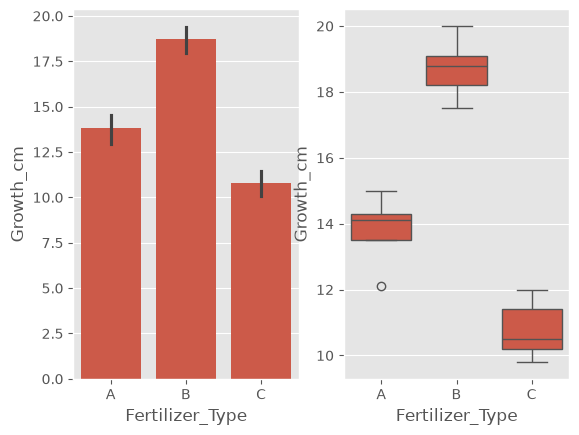

In [16]:
plt.subplot(1,2,1)
sns.barplot(x=data['Fertilizer_Type'],y = data['Growth_cm'])
plt.subplot(1,2,2)
sns.boxplot(x=data['Fertilizer_Type'],y = data['Growth_cm'])

In [17]:
model = ols('Growth_cm~C(Fertilizer_Type)',data = data).fit()

In [18]:
anova_table = sm.stats.anova_lm(model,typ = 1) #typ = 1 means ONE WAY ANOVA
anova_table

,df,sum_sq,mean_sq,F,PR(>F)
C(Fertilizer_Type),2.0,160.617333,80.308667,83.394254,9.142182e-08
Residual,12.0,11.556000,0.963000,NaN,NaN


In [20]:
alpha = 0.05
f_cric = stats.f.ppf(1-alpha,2,12)
f_cric

np.float64(3.8852938346523924)

In [22]:
df1 = 2 
df2 = 20
alpha = 0.05
f_stats = 83.39
# stats.f.cdf(f_0,af1,df2) = probability that f is smaller than f_0
p_value = 1 - stats.f.cdf(f_stats,df1,df2)
p_value

np.float64(1.98150940100561e-10)

In [25]:
mean_sq = 80.308667
sum_sq = 160.617333
MSW = 11.556/12
f_stats = mean_sq/MSW
f_stats

83.3942544132918

In [27]:
f_critical = stats.f.ppf(1-alpha,df1,df2)  #since we want to know f_critical > f when - hence 1 - alpha
f_critical

np.float64(3.4928284767356312)

In [29]:
if f_stats > f_critical:
    result = 'reject null hypothesis'
else :
    result = ' not enough evidence to reject null hypothesis.'
print(result)

reject null hypothesis
